# Sales Reporting 2019 — Mini project Python

**Mục tiêu:** phân tích doanh thu, số đơn theo giờ và các cặp sản phẩm mua cùng từ 12 file CSV.

Notebook dùng thư viện chuẩn Python để xử lý dữ liệu và Matplotlib để vẽ biểu đồ. Kết quả hiển thị trực tiếp trong notebook.

## 1. Đọc và kiểm tra dữ liệu
Một dòng là một sản phẩm trong đơn. Kiểm tra đủ 12 file, schema, dòng trống, tiêu đề lặp, kiểu dữ liệu và địa chỉ. Giữ cờ trùng để kiểm tra thay vì tự suy đoán đó là lỗi.


In [1]:
"""Đọc, kiểm tra và tổng hợp dữ liệu; chỉ dùng thư viện chuẩn Python."""
from __future__ import annotations

import csv
import hashlib
import itertools
import re
from collections import Counter, defaultdict
from datetime import datetime
from decimal import Decimal, InvalidOperation
from pathlib import Path

FIELDS = ['Order ID', 'Product', 'Quantity Ordered', 'Price Each', 'Order Date', 'Purchase Address']
ADDRESS = re.compile(r'^.+,\s*([^,]+),\s*([A-Z]{2})\s+\d{5}(?:-\d{4})?$')


def load_sales(data_dir: Path):
    """Giữ dòng trùng hợp lệ, đánh dấu để kiểm tra vì chưa biết khóa dòng đơn."""
    paths = sorted(data_dir.glob('sales2019_*.csv'), key=lambda p: int(p.stem.split('_')[-1]))
    if {p.name for p in paths} != {f'sales2019_{m}.csv' for m in range(1, 13)}:
        raise ValueError('Cần đúng 12 file sales2019_1.csv ... sales2019_12.csv trong thư mục đầu vào.')
    rows, rejected, manifest, seen = [], [], [], set()
    quality = Counter()
    for path in paths:
        file_counts = Counter()
        with path.open(encoding='utf-8-sig', newline='') as stream:
            reader = csv.DictReader(stream)
            if reader.fieldnames != FIELDS:
                raise ValueError(f'{path.name}: cấu trúc cột không đúng. Cần {FIELDS}')
            for line, raw in enumerate(reader, 2):
                quality['raw_rows'] += 1
                file_counts['raw_rows'] += 1
                values = [str(raw.get(k) or '').strip() for k in FIELDS]
                reason = None
                if None in raw or any(raw.get(k) is None for k in FIELDS):
                    reason = 'malformed_row'
                elif not any(values):
                    reason = 'empty_row'
                elif values == FIELDS:
                    reason = 'repeated_header'
                elif not all(values):
                    reason = 'missing_value'
                if reason is None:
                    order_id, product, qty_text, price_text, date_text, address = values
                    try:
                        qty = Decimal(qty_text)
                        price = Decimal(price_text)
                        if not qty.is_finite() or not price.is_finite():
                            raise ValueError('non-finite')
                        if qty <= 0 or qty != qty.to_integral_value() or price <= 0:
                            raise ValueError('non-positive or fractional quantity')
                        if price * 100 != (price * 100).to_integral_value():
                            raise ValueError('price exceeds cent precision')
                        quantity, price_cents = int(qty), int(price * 100)
                    except (InvalidOperation, ValueError):
                        reason = 'invalid_number'
                    if reason is None:
                        try:
                            date = datetime.strptime(date_text, '%m/%d/%y %H:%M')
                        except ValueError:
                            reason = 'invalid_date'
                    if reason is None:
                        location = ADDRESS.fullmatch(address)
                        if not order_id.isdigit():
                            reason = 'invalid_order_id'
                        elif not location:
                            reason = 'invalid_address'
                if reason:
                    quality[reason] += 1
                    file_counts['rejected_rows'] += 1
                    rejected.append(dict(zip(FIELDS, values), source_file=path.name, source_row=line, rejection_reason=reason))
                    continue
                signature = tuple(values)
                duplicate = signature in seen
                seen.add(signature)
                quality['exact_duplicate_rows_retained'] += int(duplicate)
                quality['valid_rows'] += 1
                file_counts['valid_rows'] += 1
                rows.append(dict(order_id=order_id, product=product, quantity=quantity,
                                 price_cents=price_cents, sales_cents=quantity * price_cents,
                                 order_date=date.isoformat(sep=' '), year=date.year,
                                 month=date.month, hour=date.hour,
                                 city=f'{location[1].strip()} ({location[2]})',
                                 purchase_address=address, source_file=path.name,
                                 source_row=line, exact_duplicate=duplicate))
        manifest.append(dict(file=path.name, bytes=path.stat().st_size,
                             sha256=hashlib.sha256(path.read_bytes()).hexdigest(), **file_counts))
    quality['rejected_rows'] = len(rejected)
    assert quality['raw_rows'] == len(rows) + len(rejected)
    return rows, rejected, dict(quality), manifest


def summarize(rows, year=2019):
    """Một Order ID là một đơn; kiểm tra tính nhất quán trước khi tổng hợp."""
    selected = [r for r in rows if r['year'] == year]
    if not selected:
        raise ValueError(f'Không có dữ liệu hợp lệ cho năm {year}.')
    orders = defaultdict(list)
    for row in selected:
        orders[row['order_id']].append(row)
    conflicts = [oid for oid, items in orders.items()
                 if len({(r['order_date'], r['purchase_address']) for r in items}) != 1]
    if conflicts:
        raise ValueError(f'Order ID có thời gian/địa chỉ mâu thuẫn: {conflicts[:5]}')
    def aggregate(key, domain=None):
        groups = defaultdict(list)
        for row in selected:
            groups[row[key]].append(row)
        return [dict(label=value, sales_cents=sum(r['sales_cents'] for r in groups[value]),
                     quantity=sum(r['quantity'] for r in groups[value]),
                     orders=len({r['order_id'] for r in groups[value]}),
                     line_items=len(groups[value])) for value in (domain if domain is not None else sorted(groups))]
    monthly = aggregate('month', range(1, 13))
    cities = sorted(aggregate('city'), key=lambda r: (-r['sales_cents'], r['label']))
    hourly = aggregate('hour', range(24))
    products = sorted(aggregate('product'), key=lambda r: (-r['quantity'], r['label']))
    pair_counts, product_orders = Counter(), Counter()
    for items in orders.values():
        basket = sorted({r['product'] for r in items})
        product_orders.update(basket)
        pair_counts.update(itertools.combinations(basket, 2))
    pairs = [dict(product_a=a, product_b=b, orders=count,
                  support=count / len(orders),
                  confidence_a_to_b=count / product_orders[a],
                  confidence_b_to_a=count / product_orders[b],
                  lift=count * len(orders) / (product_orders[a] * product_orders[b]))
             for (a, b), count in sorted(pair_counts.items(), key=lambda kv: (-kv[1], kv[0]))]
    total = sum(r['sales_cents'] for r in selected)
    for grouping in (monthly, cities, hourly, products):
        assert sum(r['sales_cents'] for r in grouping) == total
    assert sum(r['orders'] for r in hourly) == len(orders)
    assert sum(r['orders'] for r in monthly) == len(orders)
    return dict(year=year, sales_cents=total, valid_line_items=len(selected),
                orders=len(orders), quantity=sum(r['quantity'] for r in selected),
                excluded_other_year_rows=len(rows)-len(selected),
                duplicate_rows_retained=sum(r['exact_duplicate'] for r in selected),
                aov_cents=total / len(orders), monthly=monthly, cities=cities,
                hourly=hourly, products=products, pairs=pairs)


ROOT = Path.cwd()
DATA_DIR = ROOT / 'data'
if not (DATA_DIR / 'sales2019_1.csv').exists():
    raise RuntimeError('Mở notebook từ thư mục gốc repo chứa data/sales2019_1.csv.')
import json
rows, rejected, quality, manifest = load_sales(DATA_DIR)
print(json.dumps(quality, indent=2, ensure_ascii=False))
print('Số file:', len(manifest))

{
  "raw_rows": 186850,
  "exact_duplicate_rows_retained": 264,
  "valid_rows": 185950,
  "empty_row": 545,
  "repeated_header": 355,
  "rejected_rows": 900
}
Số file: 12


## 2. Xác định phạm vi và chỉ tiêu
Chỉ chọn năm 2019 theo ngày đặt hàng thực tế. Tiền được tính bằng cent nguyên; số đơn là số Order ID duy nhất, không phải số dòng. Các dòng ngoài năm vẫn còn trong dữ liệu sạch.


In [2]:
summary = summarize(rows, year=2019)
print(f"Doanh thu: ${summary['sales_cents']/100:,.2f}")
print(f"Số đơn: {summary['orders']:,}")
print(f"Số lượng sản phẩm: {summary['quantity']:,}")
print(f"Dòng ngoài năm phân tích: {summary['excluded_other_year_rows']:,}")
assert sum(r['sales_cents'] for r in summary['monthly']) == summary['sales_cents']
assert sum(r['orders'] for r in summary['hourly']) == summary['orders']


Doanh thu: $34,483,365.68
Số đơn: 178,406
Số lượng sản phẩm: 209,038
Dòng ngoài năm phân tích: 34


## 3. Chuẩn bị biểu đồ
Dùng Matplotlib để vẽ trực tiếp từ các bảng tổng hợp đã tính ở trên.

In [3]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter


def plot_bars(labels, values, *, title, unit, horizontal=False, money=False):
    """Vẽ biểu đồ cột từ kết quả tổng hợp Python."""
    height = max(4, 0.42 * len(labels) + 1.5) if horizontal else 4.5
    fig, ax = plt.subplots(figsize=(11, height), layout='constrained')
    formatter = StrMethodFormatter('${x:,.0f}' if money else '{x:,.0f}')

    if horizontal:
        ax.barh(labels, values, color='#087f8c')
        ax.invert_yaxis()
        ax.set_xlabel(unit)
        ax.xaxis.set_major_formatter(formatter)
        ax.grid(axis='x', alpha=0.2)
    else:
        ax.bar(labels, values, color='#087f8c')
        ax.set_ylabel(unit)
        ax.yaxis.set_major_formatter(formatter)
        ax.grid(axis='y', alpha=0.2)

    ax.set_title(title, loc='left', fontweight='bold')
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    plt.show()
    plt.close(fig)

## 4. Tháng nào có doanh thu cao nhất?
Lấy năm và tháng từ ngày đặt hàng để tránh gộp các ngày tháng 1/2020 vào tháng 1/2019.


Tháng 12: $4,613,443.34


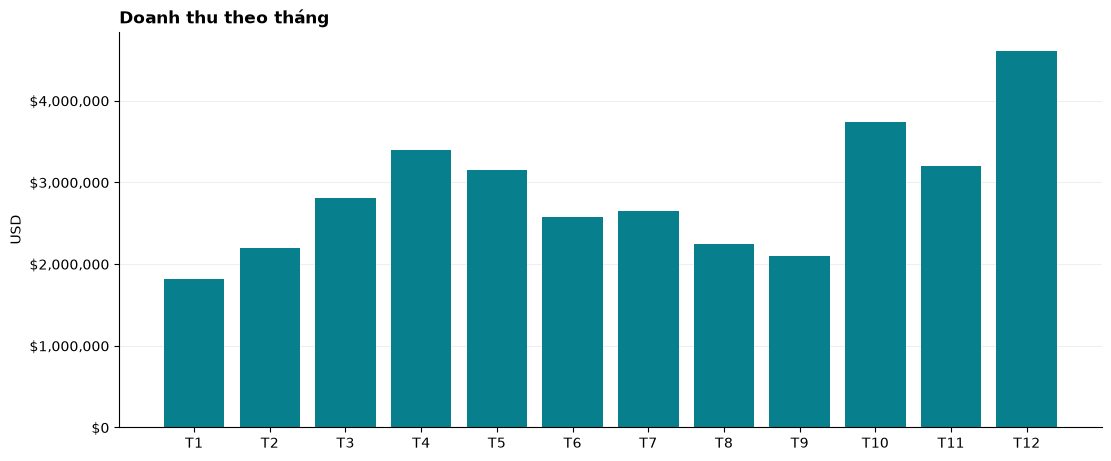

In [4]:
best = max(summary['monthly'], key=lambda r: r['sales_cents'])
print(f"Tháng {best['label']}: ${best['sales_cents']/100:,.2f}")

monthly = summary['monthly']
plot_bars([f"T{r['label']}" for r in monthly],
          [r['sales_cents'] / 100 for r in monthly],
          title='Doanh thu theo tháng', unit='USD', money=True)

## 5. Thành phố nào có doanh thu cao nhất?
Tách thành phố theo bang để giữ riêng Portland (OR) và Portland (ME). Doanh thu cao chưa có nghĩa thị trường có ROI cao.


San Francisco (CA) $8,259,719.03


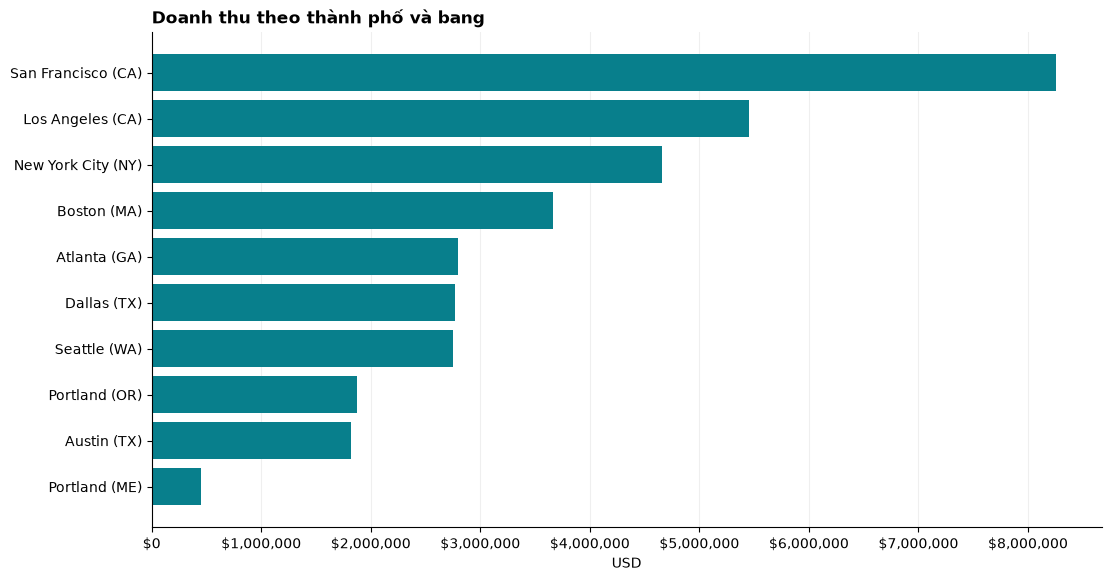

In [5]:
best = summary['cities'][0]
print(best['label'], f"${best['sales_cents']/100:,.2f}")

cities = summary['cities']
plot_bars([r['label'] for r in cities], [r['sales_cents'] / 100 for r in cities],
          title='Doanh thu theo thành phố và bang', unit='USD', horizontal=True, money=True)

## 6. Giờ nào có nhiều đơn nhất?
Đếm đơn duy nhất theo giờ đặt hàng, không đếm dòng sản phẩm. Dữ liệu không có múi giờ hoặc kết quả quảng cáo.

19:00 — 12,377 đơn
12:00 — 12,082 đơn
11:00 — 11,882 đơn


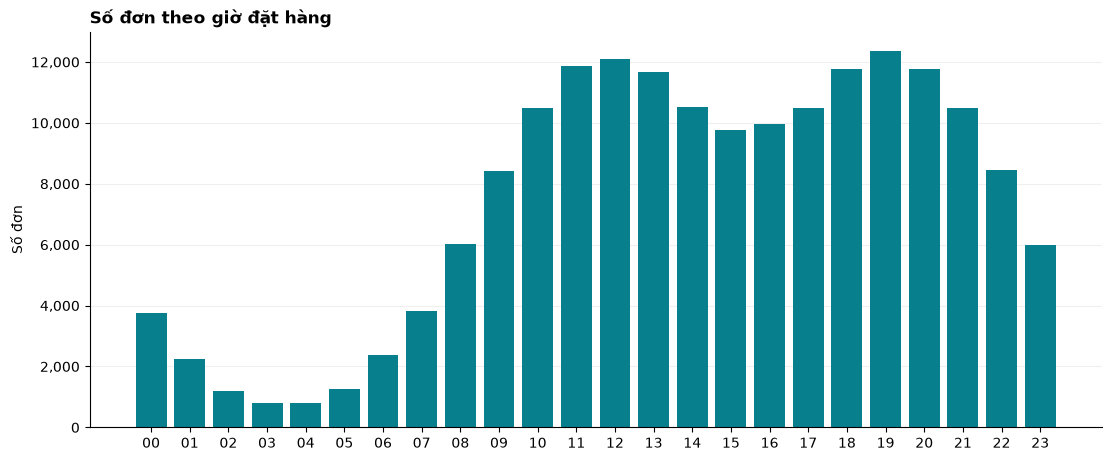

In [6]:
for row in sorted(summary['hourly'], key=lambda r: (-r['orders'], r['label']))[:3]:
    print(f"{row['label']:02d}:00 — {row['orders']:,} đơn")

hourly = summary['hourly']
plot_bars([f"{r['label']:02d}" for r in hourly], [r['orders'] for r in hourly],
          title='Số đơn theo giờ đặt hàng', unit='Số đơn')

## 7. Sản phẩm nào thường được mua cùng?
Mỗi cặp được tính tối đa một lần trong một đơn hàng. Biểu đồ hiển thị 10 cặp có nhiều đơn nhất.

Lightning Charging Cable + iPhone | 1010 đơn | support 0.57% | lift 1.22
Google Phone + USB-C Charging Cable | 997 đơn | support 0.56% | lift 1.47
Wired Headphones + iPhone | 462 đơn | support 0.26% | lift 0.64
Google Phone + Wired Headphones | 422 đơn | support 0.24% | lift 0.72
Apple Airpods Headphones + iPhone | 372 đơn | support 0.21% | lift 0.63


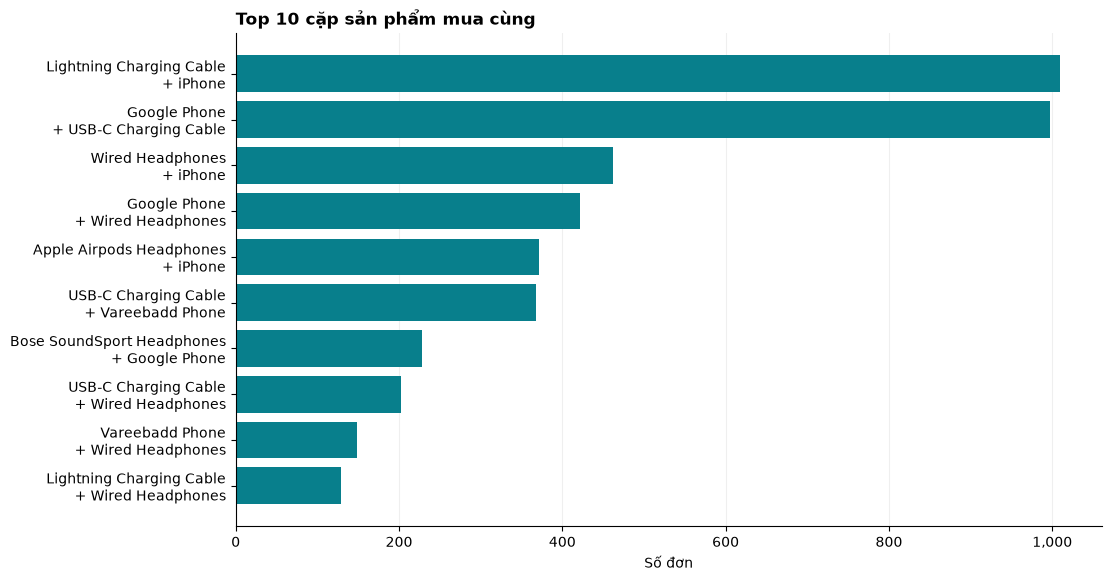

In [7]:
for row in summary['pairs'][:5]:
    print(row['product_a'], '+', row['product_b'], '|', row['orders'], 'đơn',
          '| support', f"{row['support']:.2%}", '| lift', f"{row['lift']:.2f}")

pairs = summary['pairs'][:10]
if pairs:
    labels = [f"{r['product_a']}\n+ {r['product_b']}" for r in pairs]
    plot_bars(labels, [r['orders'] for r in pairs],
              title='Top 10 cặp sản phẩm mua cùng', unit='Số đơn', horizontal=True)
else:
    print('Không có cặp sản phẩm mua cùng.')

## 8. Sản phẩm nào bán được nhiều nhất?
Xếp theo số lượng sản phẩm bán được, không xếp theo doanh thu.

AAA Batteries (4-pack) | 31,012 sản phẩm
AA Batteries (4-pack) | 27,635 sản phẩm
USB-C Charging Cable | 23,971 sản phẩm
Lightning Charging Cable | 23,211 sản phẩm
Wired Headphones | 20,553 sản phẩm


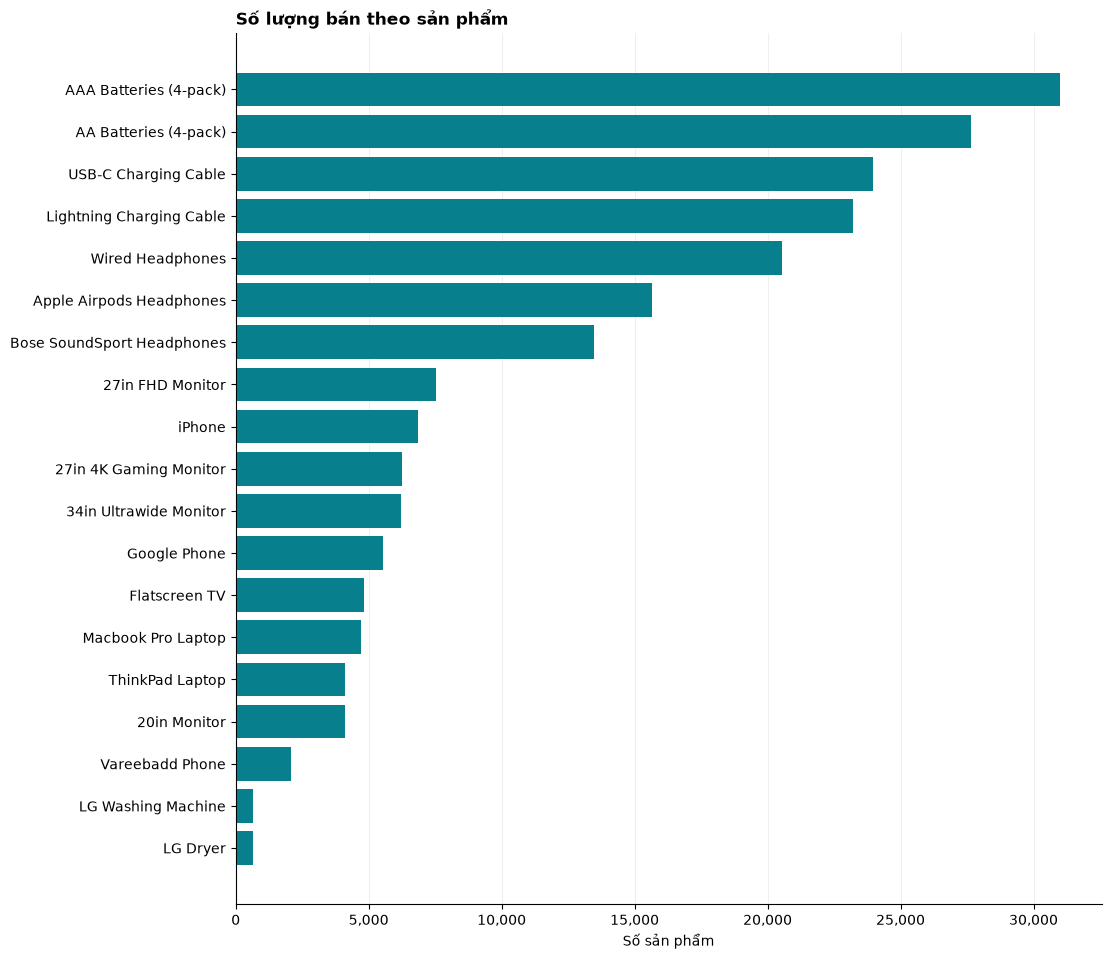

In [8]:
for row in summary['products'][:5]:
    print(row['label'], '|', f"{row['quantity']:,}", 'sản phẩm')

products = summary['products']
plot_bars([r['label'] for r in products], [r['quantity'] for r in products],
          title='Số lượng bán theo sản phẩm', unit='Số sản phẩm', horizontal=True)